# Path A: class-conditional mel-spectrogram diffusion

Trains a 2D UNet DDPM on log-mel spectrograms and writes a checkpoint plus a file of
generated samples to Drive. Everything shared with the other paths (data, split, crops,
front end, training loop, sampler) comes from `common.py`. This notebook defines only the
model and how it is called.

Set `QUICK_TEST = True` first to run the whole notebook in a few minutes.

## 1. Setup

In [1]:
!pip install -q diffusers accelerate soundfile

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os, sys
REPO_DIR = "/content/thesis"
if not os.path.exists(REPO_DIR):
    !git clone -q https://github.com/1jvaldez1/audio-diffusion-synth.git {REPO_DIR}
else:
    !git -C {REPO_DIR} pull -q
sys.path.insert(0, REPO_DIR)
import common as C
import subprocess
import matplotlib.pyplot as plt
import torch
from diffusers import UNet2DModel

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


## 2. Config

All shared settings live in `C.Config`. Only the values listed here are specific to Path A.

In [5]:
QUICK_TEST = False          # True: short run to check the notebook end to end

N_MELS     = 64             # mel bands; 64 is the baseline run, 128 is the higher-resolution run

cfg = C.Config(n_mels=N_MELS, total_steps=300, inference_steps=20) if QUICK_TEST else C.Config(n_mels=N_MELS)
TAG = (f"_{N_MELS}mel" if N_MELS != 64 else "") + ("_quick" if QUICK_TEST else "")
C.seed_everything(cfg.seed)

# Path A model settings
DROPOUT          = 0.1
USE_FREQ_CHANNEL = False    # ablation: feed a frequency-position ramp as a second input channel
GUIDANCE         = 1.0      # 1.0 = plain conditional sampling; keep at 1.0 for distribution metrics
N_PER_CLASS      = 2 if QUICK_TEST else 16   # 16 x 50 classes = 800, the size of the held-out reference set

RUN_DIR       = f"{cfg.out_root}/path_a{TAG}"
SAMPLES_FILE  = f"{cfg.out_root}/samples/path_a{TAG}.pt"

# The 64-band front end is shared by every path; other band counts get their own file,
# because the dB window is calibrated per band layout.
FRONTEND_FILE = f"{cfg.out_root}/frontend.json" if N_MELS == 64 else f"{cfg.out_root}/frontend_{N_MELS}mel.json"
SAMPLE_SHAPE  = (1, cfg.n_mels, cfg.spec_frames)

print(f"clip: {cfg.clip_seconds:.2f} s -> spectrogram {cfg.n_mels} x {cfg.spec_frames}")

clip: 2.03 s -> spectrogram 64 x 128


## 3. Data and front end

Training uses ESC-50 folds 1-4; fold 5 is held out and never seen by the model. The mel
front end is calibrated once on the training split and saved, so every path notebook and
the evaluation notebook apply the same transform.

In [6]:
data = C.load_esc50(cfg)
train_split, val_split, heldout_split = C.split_by_fold(data, cfg)
train_set = C.CropDataset(train_split, cfg)
print(f"train clips: {len(train_split['waveforms'])} | val clips: {len(val_split['waveforms'])} | held-out clips: {len(heldout_split['waveforms'])}")

if os.path.exists(FRONTEND_FILE):
    frontend = C.MelFrontEnd.load(FRONTEND_FILE, cfg, device=device)
else:
    frontend = C.MelFrontEnd(cfg, device=device).fit(train_split["waveforms"])
    frontend.save(FRONTEND_FILE)
print(f"dB window: [{frontend.db_max - cfg.db_range:.1f}, {frontend.db_max:.1f}]")

train clips: 1200 | val clips: 400 | held-out clips: 400
dB window: [-40.8, 39.2]


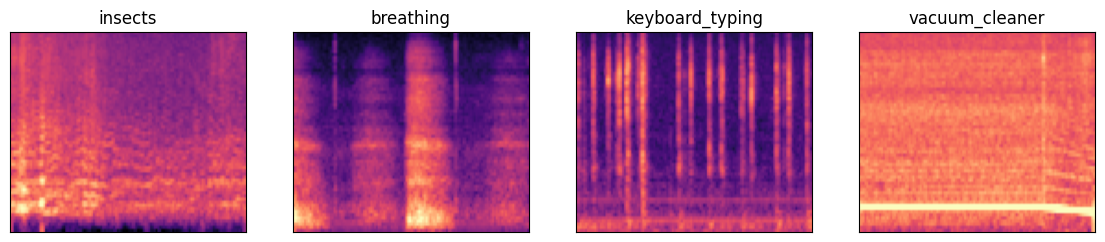

In [7]:
# Check the crops: four random training examples
fig, axes = plt.subplots(1, 4, figsize=(14, 2.6))
for ax in axes:
    wave, label = train_set[torch.randint(len(train_set), (1,)).item()]
    ax.imshow(frontend(wave[None])[0, 0].cpu(), origin="lower", aspect="auto", cmap="magma", vmin=-1, vmax=1)
    ax.set_title(data["class_names"][label]); ax.set_xticks([]); ax.set_yticks([])
plt.show()

## 4. Model

A three-level UNet (64 / 128 / 256 channels, two ResNet layers per level). The input
64 x 128 is halved twice to 16 x 32, where self-attention runs over 512 positions.

| Choice | Reason |
|---|---|
| Three levels, attention only at the coarsest | Global structure (onsets, harmonic spacing) is resolved at 16 x 32, where attention is cheap. Fine texture is local, and convolutions handle it. |
| `num_class_embeds = classes + 1` | One embedding per class plus a "no label" entry. The class embedding is added to the timestep embedding, so it reaches every ResNet block. |
| `resnet_time_scale_shift="scale_shift"` | The conditioning scales and shifts the normalised features instead of only adding to them (the ADM design). |
| `attention_head_dim=32` | 8 heads of width 32 at 256 channels. The default of 8 would give 32 very narrow heads. |
| `dropout=0.1` | Regularisation for a small dataset. |
| One output channel | The model predicts the v-target for the spectrogram only; the optional frequency ramp is an input hint. |

In [8]:
def build_unet_a(cfg, use_freq_channel=False, dropout=0.1):
    return UNet2DModel(
        sample_size=(cfg.n_mels, cfg.spec_frames),
        in_channels=2 if use_freq_channel else 1,
        out_channels=1,
        layers_per_block=2,
        block_out_channels=(64, 128, 256),
        norm_num_groups=32,
        dropout=dropout,
        attention_head_dim=32,
        resnet_time_scale_shift="scale_shift",
        num_class_embeds=cfg.num_classes + 1,
        down_block_types=("DownBlock2D", "DownBlock2D", "AttnDownBlock2D"),
        up_block_types=("AttnUpBlock2D", "UpBlock2D", "UpBlock2D"),
    )

# Fixed ramp from -1 (lowest mel bin) to +1 (highest), constant over time
freq_pos = torch.linspace(-1, 1, cfg.n_mels, device=device).view(1, 1, cfg.n_mels, 1).expand(1, 1, cfg.n_mels, cfg.spec_frames)

def forward_fn(model, x, t, labels):
    if USE_FREQ_CHANNEL:
        x = torch.cat([x, freq_pos.expand(x.shape[0], -1, -1, -1).to(x.dtype)], dim=1)
    return model(x, t, class_labels=labels).sample

unet_a = build_unet_a(cfg, USE_FREQ_CHANNEL, DROPOUT).to(device)
n_params = sum(p.numel() for p in unet_a.parameters())
print(f"Path A params: {n_params:,}")

Path A params: 16,442,433


## 5. Train

The loop resumes from `RUN_DIR/last.pt` if it exists. After a disconnect, rerun the
notebook from the top and training continues from the last checkpoint. If training has
already finished, this cell returns immediately with the saved weights.

To start a fresh run, delete or rename `RUN_DIR` first.

Resumed from step 10000


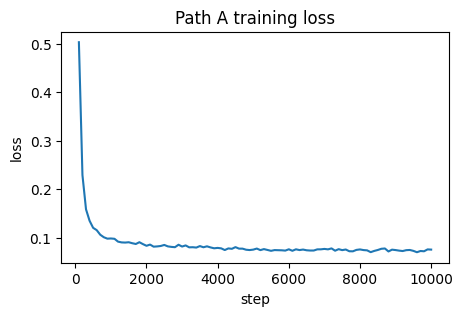

In [9]:
ema, losses = C.train_diffusion(unet_a, forward_fn, frontend, train_set, cfg, RUN_DIR, device)

plt.figure(figsize=(5, 3))
plt.plot([cfg.log_every * (i + 1) for i in range(len(losses))], losses)
plt.xlabel("step"); plt.ylabel("loss"); plt.title("Path A training loss")
plt.show()

In [10]:
scheduler, _ = C.make_schedulers(cfg)
ema.store(unet_a.parameters()); ema.copy_to(unet_a.parameters()); unet_a.eval()
batch = [train_set[i] for i in range(128)]
x0 = frontend(torch.stack([b[0] for b in batch]).to(device))
labels = torch.stack([b[1] for b in batch]).to(device)
var = x0.var(dim=(0, 1, 3)).cpu()
err, base = torch.zeros(cfg.n_mels), torch.zeros(cfg.n_mels)
with torch.no_grad():
    for t_val in (100, 300, 500, 700, 900):
        t = torch.full((len(x0),), t_val, device=device)
        noise = torch.randn_like(x0)
        pred = forward_fn(unet_a, scheduler.add_noise(x0, noise, t), t, labels)
        err += ((pred - scheduler.get_velocity(x0, noise, t)) ** 2).mean(dim=(0, 1, 3)).cpu() / 5
        ac = scheduler.alphas_cumprod[t_val].item(); a, b = ac ** 0.5, (1 - ac) ** 0.5
        base += ((a**2 + b**2 * var) - (a * b * (1 - var)) ** 2 / (a**2 * var + b**2)) / 5
ema.restore(unet_a.parameters())
rel = err / base.clamp(min=1e-8)
print(f"Path A ({cfg.n_mels} bands) variance-weighted relative v-loss: {(rel * var).sum() / var.sum():.3f}  (64 bands: 0.105, B-latent: 0.867)")

Path A variance-weighted relative v-loss: 0.105  (B-latent: 0.867)


## 6. Generate and save samples

A class-balanced set, sampled from the EMA weights with DDIM. The evaluation notebook reads
`SAMPLES_FILE`; nothing is scored here.

In [11]:
commit = subprocess.check_output(["git", "-C", REPO_DIR, "rev-parse", "--short", "HEAD"]).decode().strip()

gen_labels = C.balanced_labels(cfg, N_PER_CLASS)
generated = C.sample(unet_a, forward_fn, SAMPLE_SHAPE, cfg, device,
                     labels=gen_labels, ema=ema, guidance=GUIDANCE)

meta = dict(path="A", guidance=GUIDANCE, steps=cfg.inference_steps,
               use_freq_channel=USE_FREQ_CHANNEL, n_params=n_params, train_steps=cfg.total_steps, commit=commit)
C.save_samples(SAMPLES_FILE, generated, gen_labels, cfg, representation="mel", **meta)

print("saved", tuple(generated.shape), "->", SAMPLES_FILE)
print(f"value range: [{generated.min():.3f}, {generated.max():.3f}]")

saved (800, 1, 64, 128) -> /content/drive/MyDrive/thesis_runs/samples/path_a.pt
value range: [-1.000, 1.000]


## 7. Visual check

Held-out real spectrograms (top) against generated ones of the same class (bottom). This is
a sanity check only.

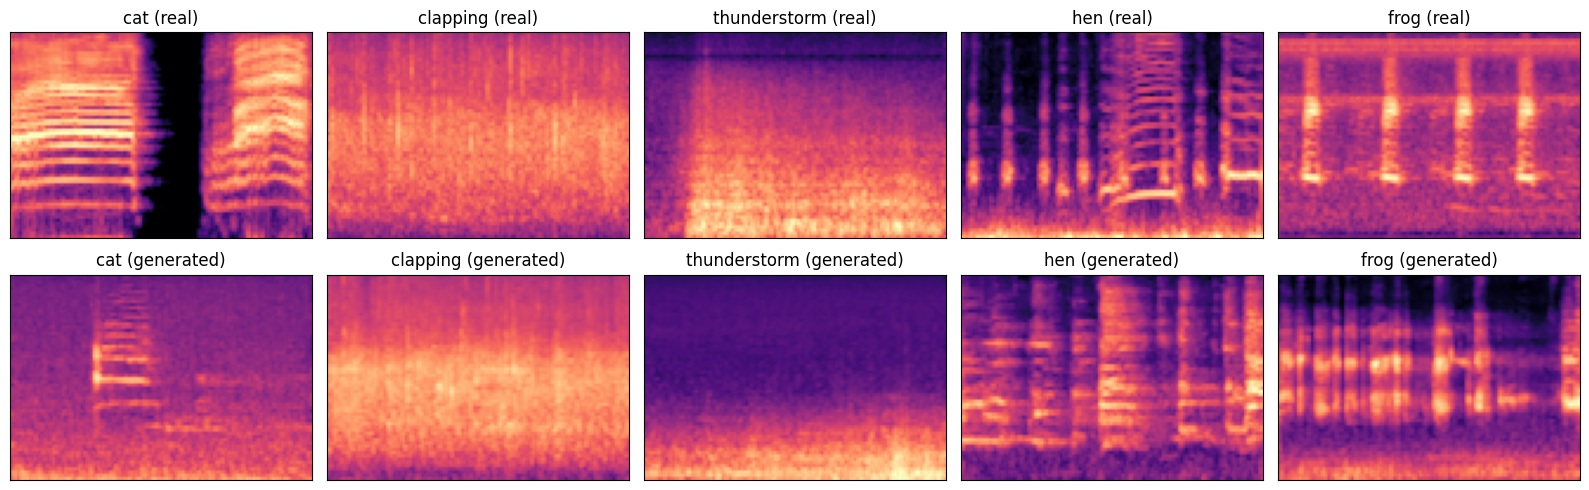

In [12]:
ref_wave, ref_labels = C.reference_crops(val_split, cfg, k=1)
show = torch.randperm(cfg.num_classes)[:5].tolist()

fig, axes = plt.subplots(2, 5, figsize=(16, 5))
for col, c in enumerate(show):
    real = frontend(ref_wave[ref_labels == c][:1])[0, 0].cpu()
    fake = generated[gen_labels == c][0, 0]
    for row, (img, tag) in enumerate([(real, "real"), (fake, "generated")]):
        axes[row, col].imshow(img, origin="lower", aspect="auto", cmap="magma", vmin=-1, vmax=1)
        axes[row, col].set_title(f"{data['class_names'][c]} ({tag})")
        axes[row, col].set_xticks([]); axes[row, col].set_yticks([])
plt.tight_layout(); plt.show()

## 8. Look and listen

In [13]:
from IPython.display import Audio, display
for c in show[:3]:
    real = ref_wave[ref_labels == c][:1]
    real_gl = C.spec_to_wave(frontend(real.to(device)).cpu(), frontend, n_iter=64)   # real audio through mel + Griffin-Lim
    gen_gl  = C.spec_to_wave(generated[gen_labels == c][:2], frontend, n_iter=64)    # two generated samples
    print(data["class_names"][c], "- real, real via mel + Griffin-Lim, then two generated")
    display(Audio(real[0, 0].numpy(), rate=cfg.sample_rate))
    display(Audio(real_gl[0, 0].numpy(), rate=cfg.sample_rate))
    for j in range(2):
        display(Audio(gen_gl[j, 0].numpy(), rate=cfg.sample_rate))

cat - real, real via mel + Griffin-Lim, then two generated


clapping - real, real via mel + Griffin-Lim, then two generated


thunderstorm - real, real via mel + Griffin-Lim, then two generated
